<a href="https://colab.research.google.com/github/tanmaiduddukuri-dot/DLAC/blob/main/DLAC%20CO%201.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VisionPort – Intelligent Vehicle Detection & Traffic Monitoring (Google Colab)

**How to use this notebook**
1. `Runtime → Change runtime type → T4 GPU` (free tier is fine).
2. Run the cells **top to bottom**. Each task has its own section and produces the output listed in your task table.
3. Upload your own traffic video (a 20–60 s clip from a fixed camera works best) when asked, or mount Google Drive.
4. Tasks 9–20 use zones/lines defined as *fractions of the frame* in the **Configuration** cell. Use the grid preview to adjust them to your camera view.

Videos you can use: your own CCTV/phone clip, free stock clips (Pexels, Pixabay), or the public UA-DETRAC dataset.
All outputs are saved to `/content/outputs/`, and the last cell zips them for download.

## Task 1 – Install Python libraries (working environment)

In [ ]:
!pip -q install ultralytics lapx
import cv2, os, math, time, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from base64 import b64encode
from IPython.display import HTML, display
from google.colab import files
from google.colab.patches import cv2_imshow
import torch, ultralytics

print("OpenCV:", cv2.__version__)
print("Ultralytics:", ultralytics.__version__)
print("GPU available:", torch.cuda.is_available())
OUT = Path("/content/outputs"); OUT.mkdir(exist_ok=True, parents=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
OpenCV: 5.0.0
Ultralytics: 8.4.215
GPU available: False


## Task 2 – Capture a traffic-signal image with a camera
Colab runs in the cloud, so the "camera" is your **browser webcam** (point it at a screen/photo) or, better, **upload a photo from your phone**. Run either option.

In [ ]:
from IPython.display import Javascript
from google.colab.output import eval_js
from base64 import b64decode
from google.colab import files

def take_photo(filename="traffic_capture.jpg", quality=0.9):
    js = Javascript("""
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => capture.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    """)
    display(js)
    data = eval_js("takePhoto({})".format(quality))
    with open(filename, "wb") as f:
        f.write(b64decode(data.split(",")[1]))
    return filename

# OPTION A: webcam capture (allow camera access in the browser)
# take_photo("traffic_capture.jpg")

# OPTION B: upload a photo taken on your phone
up = files.upload()
IMAGE = list(up.keys())[0]
print("Image saved as:", IMAGE)

Saving DSCN2705.JPG to DSCN2705.JPG
Image saved as: DSCN2705.JPG


## Task 3 – Read and display a traffic image with OpenCV

In [ ]:
img = cv2.imread(IMAGE)
assert img is not None, "Could not read the image - check the file name in IMAGE"
print("Shape (H, W, channels):", img.shape)
cv2_imshow(img)   # Colab replacement for cv2.imshow()

## Task 4 – Load and play a traffic video
Upload your video (or set `VIDEO` to a path in Google Drive after `drive.mount`).

In [ ]:
from google.colab import files
# from google.colab import drive; drive.mount('/content/drive'); VIDEO = "/content/drive/MyDrive/traffic.mp4"
up = files.upload()
VIDEO = list(up.keys())[0]

cap = cv2.VideoCapture(VIDEO)
assert cap.isOpened(), "Cannot open video"
print("FPS:", cap.get(cv2.CAP_PROP_FPS),
      "| Frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
      "| Size:", int(cap.get(3)), "x", int(cap.get(4)))
cap.release()

def show_video(path, width=700, seconds=20):
    """Re-encode to H.264 so the browser can play it, then embed it."""
    tmp = "/content/_preview.mp4"
    os.system(f'ffmpeg -y -loglevel error -t {seconds} -i "{path}" -vcodec libx264 -pix_fmt yuv420p "{tmp}"')
    data = b64encode(open(tmp, "rb").read()).decode()
    display(HTML(f'<video width="{width}" controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>'))

show_video(VIDEO)

## Task 5 – Extract frames from the traffic video

Saved 165 frames to /content/frames


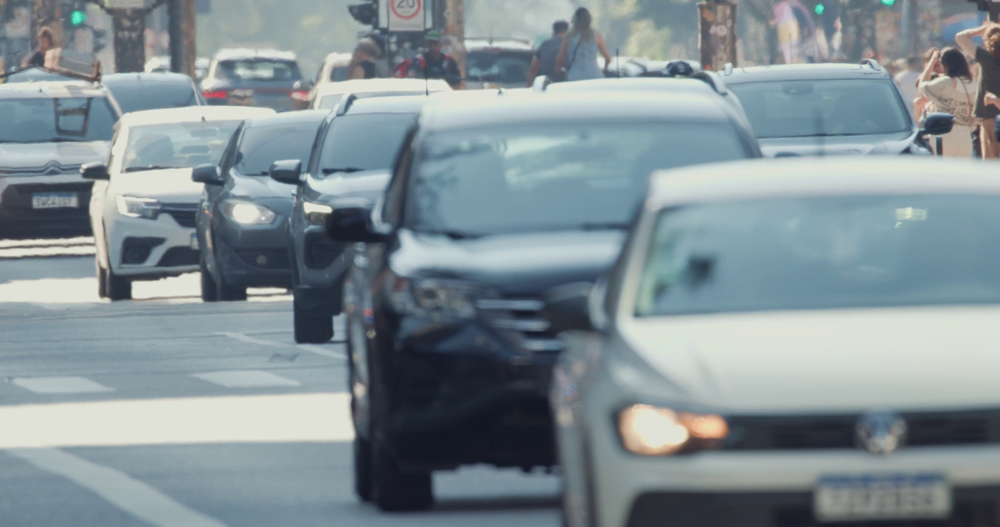

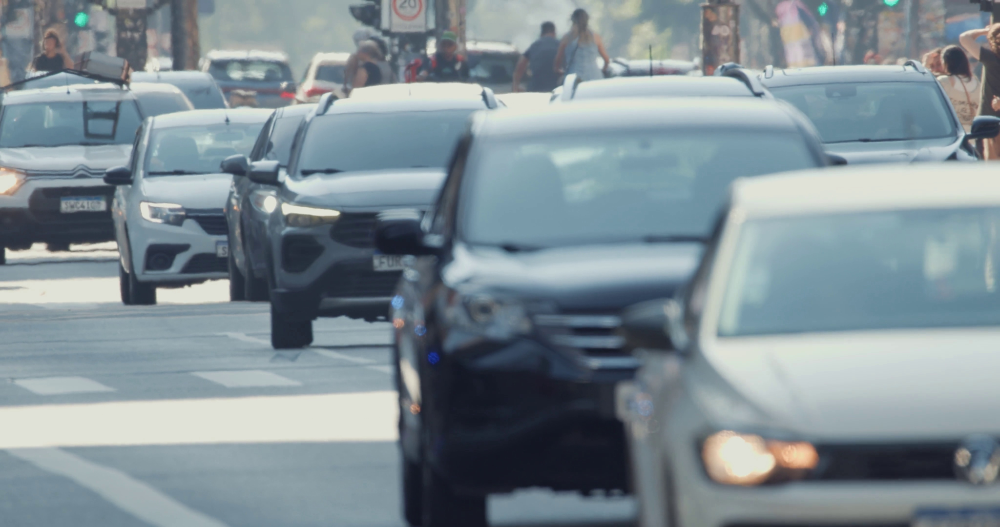

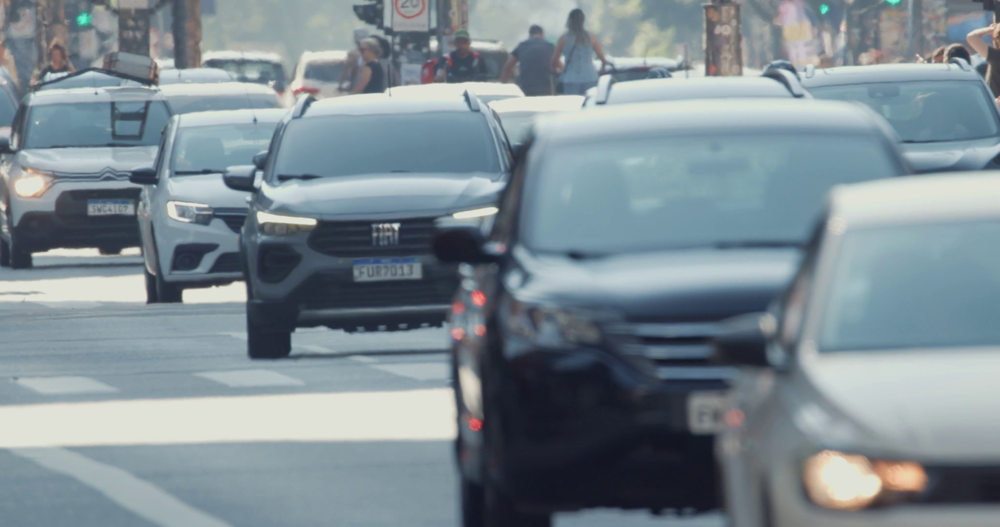

In [ ]:
def extract_frames(video, out_dir="frames", every_n=30, max_saved=None):
    os.makedirs(out_dir, exist_ok=True)
    cap = cv2.VideoCapture(video); i = saved = 0
    while True:
        ok, f = cap.read()
        if not ok: break
        if i % every_n == 0:
            cv2.imwrite(f"{out_dir}/frame_{i:06d}.jpg", f); saved += 1
            if max_saved and saved >= max_saved: break
        i += 1
    cap.release()
    return saved

n = extract_frames(VIDEO, "frames", every_n=30)
print("Saved", n, "frames to /content/frames")
for p in sorted(Path("frames").glob("*.jpg"))[:3]:
    cv2_imshow(cv2.resize(cv2.imread(str(p)), None, fx=0.5, fy=0.5))
!zip -qr frames.zip frames   # download later with files.download("frames.zip")

## Task 6 – Detect cars with YOLO
We use pretrained YOLOv8 (COCO classes: car=2, motorcycle=3, bus=5, truck=7, person=0, traffic light=9). For better accuracy swap `yolov8n.pt` for `yolov8s.pt` or `yolov8m.pt`.

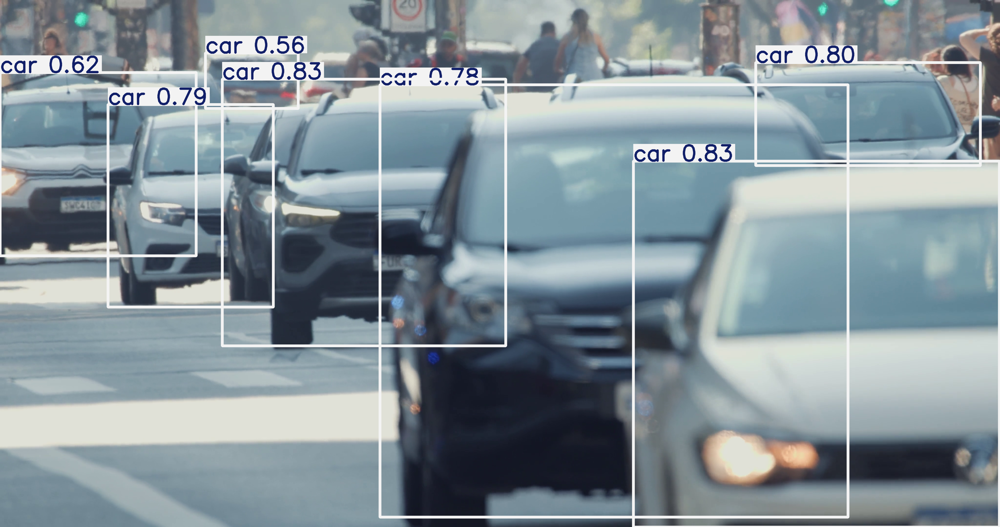

Cars detected: 7


In [ ]:
from ultralytics import YOLO
model = YOLO("yolov8n.pt")

VEHICLE_CLASSES = {2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}
VEH_IDS = list(VEHICLE_CLASSES.keys())
COLORS = {2: (0, 200, 0), 3: (255, 120, 0), 5: (0, 140, 255), 7: (200, 0, 200), 0: (255, 255, 0)}
FONT = cv2.FONT_HERSHEY_SIMPLEX

def get_frame(video, n=30):
    cap = cv2.VideoCapture(video); cap.set(cv2.CAP_PROP_POS_FRAMES, n)
    ok, f = cap.read(); cap.release()
    assert ok, "Could not read that frame"
    return f

frame = get_frame(VIDEO, 30)
res = model.predict(frame, classes=[2], conf=0.3, verbose=False)[0]
cv2_imshow(res.plot())
print("Cars detected:", len(res.boxes))

## Task 7 – Detect bikes, buses and trucks (plus cars)

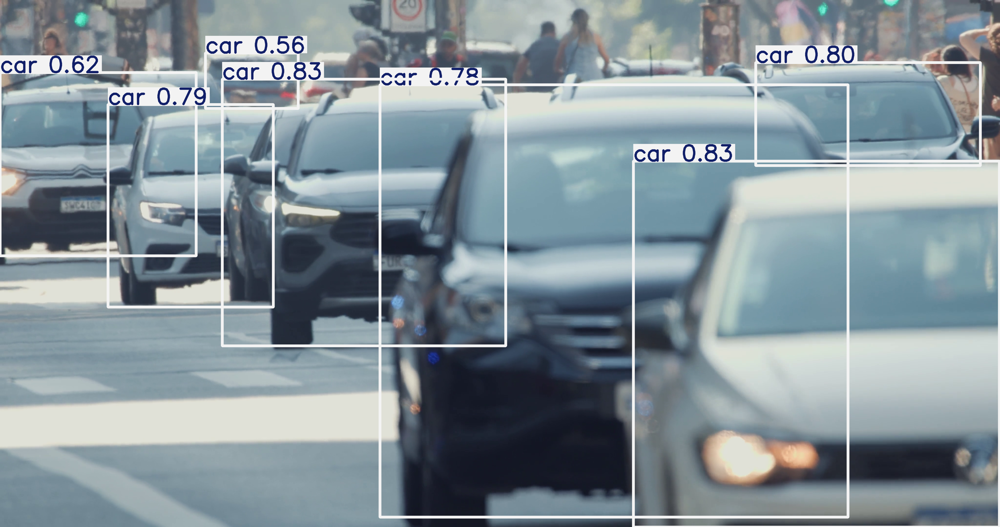

{'car': 7}


In [ ]:
res = model.predict(frame, classes=VEH_IDS, conf=0.3, verbose=False)[0]
cv2_imshow(res.plot())
print({VEHICLE_CLASSES[int(c)]: int(n) for c, n in zip(*np.unique(res.boxes.cls.cpu().numpy(), return_counts=True))})

## Task 8 – Display vehicle names and confidence scores

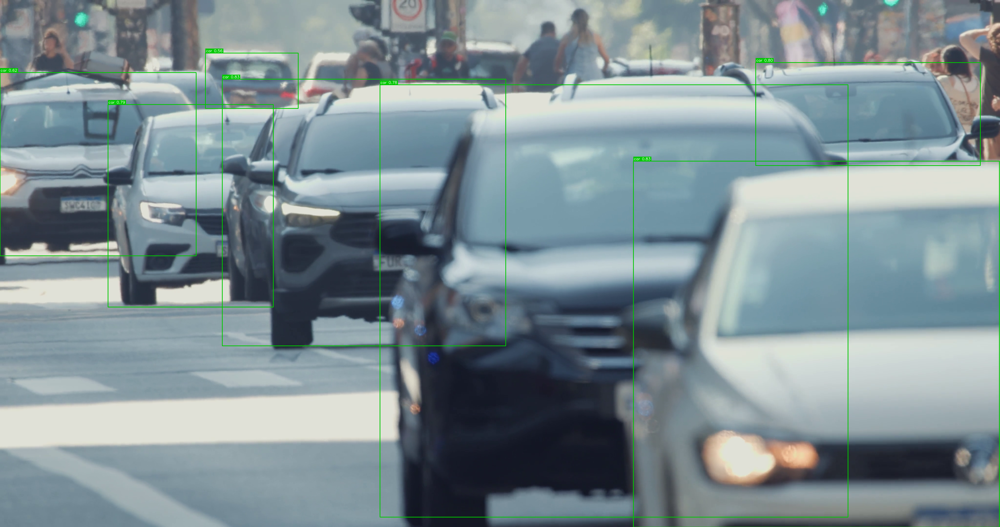

,name,conf,box
0,car,0.83,"(910, 324, 2071, 1417)"
1,car,0.83,"(2594, 660, 4093, 2160)"
2,car,0.80,"(3095, 256, 4015, 678)"
3,car,0.79,"(442, 428, 1119, 1258)"
4,car,0.78,"(1556, 347, 3473, 2119)"
5,car,0.62,"(0, 297, 803, 1048)"
6,car,0.56,"(841, 217, 1221, 444)"


In [ ]:
def color_for(c): return COLORS.get(c, (0, 255, 255))

def draw_label(img, x1, y1, x2, y2, text, color=(0, 255, 0)):
    cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
    (tw, th), _ = cv2.getTextSize(text, FONT, 0.5, 1)
    cv2.rectangle(img, (x1, max(0, y1 - th - 6)), (x1 + tw + 4, y1), color, -1)
    cv2.putText(img, text, (x1 + 2, y1 - 4), FONT, 0.5, (255, 255, 255), 1, cv2.LINE_AA)

def banner(img, text, color=(0, 128, 0), y=0):
    cv2.rectangle(img, (0, y), (img.shape[1], y + 34), color, -1)
    cv2.putText(img, text, (10, y + 24), FONT, 0.75, (255, 255, 255), 2, cv2.LINE_AA)

def parse_dets(r):
    """Ultralytics result -> list of simple dicts (id is None if not tracking)."""
    dets = []
    if r.boxes is None or len(r.boxes) == 0: return dets
    ids = r.boxes.id.int().tolist() if r.boxes.id is not None else [None] * len(r.boxes)
    for b, tid in zip(r.boxes, ids):
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist()); c = int(b.cls[0])
        dets.append(dict(id=tid, cls=c, name=model.names[c], conf=float(b.conf[0]),
                         box=(x1, y1, x2, y2), cx=(x1 + x2) // 2, cy=(y1 + y2) // 2,
                         pt=((x1 + x2) // 2, y2)))   # pt = bottom-centre (ground contact point)
    return dets

dets = parse_dets(model.predict(frame, classes=VEH_IDS, conf=0.3, verbose=False)[0])
vis = frame.copy()
for d in dets:
    draw_label(vis, *d["box"], f'{d["name"]} {d["conf"]:.2f}', color_for(d["cls"]))
cv2_imshow(vis)
display(pd.DataFrame([{k: d[k] for k in ("name", "conf", "box")} for d in dets]).round(2))

## Configuration & shared helpers for Tasks 9–20
Zones and lines are written as **fractions of the frame** so they work with any resolution. Run the preview, then edit the fractions until the shapes sit on the right parts of *your* camera view.

In [ ]:
cap = cv2.VideoCapture(VIDEO)
FPS = cap.get(cv2.CAP_PROP_FPS) or 25
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)); cap.release()
MAX_FRAMES = 300            # frames processed per demo run (raise for the full video)

def P(frac_pts): return [(int(x * W), int(y * H)) for x, y in frac_pts]

# --- zones / lines (EDIT THESE for your camera view) ---
JUNCTION_ROI    = P([(0.05, 0.35), (0.95, 0.35), (1.0, 1.0), (0.0, 1.0)])        # Tasks 11, 15
COUNT_LINES     = {"Line A": P([(0.0, 0.65), (1.0, 0.65)])}                       # Task 16
ARM_ZONES       = {"N": P([(0.3, 0.0), (0.7, 0.0), (0.7, 0.3), (0.3, 0.3)]),      # Task 17
                   "S": P([(0.3, 0.7), (0.7, 0.7), (0.7, 1.0), (0.3, 1.0)]),
                   "W": P([(0.0, 0.3), (0.25, 0.3), (0.25, 0.7), (0.0, 0.7)]),
                   "E": P([(0.75, 0.3), (1.0, 0.3), (1.0, 0.7), (0.75, 0.7)])}
FORBIDDEN_TURNS = {("S", "E")}          # (origin arm, destination arm) pairs that are not allowed. ("S","S") = U-turn
LANES           = [{"poly": P([(0, 0), (1, 0), (1, 1), (0, 1)]), "dir": (0, 1)}]  # Task 18; dir=(0,1) means "downwards in image"
NO_PARKING      = P([(0.8, 0.4), (1.0, 0.4), (1.0, 1.0), (0.85, 1.0)])           # Task 19
SIGNAL_ROI      = None                  # Task 14: set (x1, y1, x2, y2) in pixels if YOLO misses the light

# --- thresholds ---
LOW_MAX, MED_MAX = 8, 20                # Task 10: <=8 LOW, <=20 MEDIUM, else HIGH
CONG_MIN, CONG_SECONDS = 12, 3          # Task 11: >=12 vehicles in the ROI for 3 s -> congestion
METERS_PER_PIXEL = 0.05                 # Task 13: calibrate! (e.g. 3.5 m lane width / lane width in pixels)
PARK_SECONDS = 10                       # Task 19
ENTRY_IS_POSITIVE = True                # Task 16: flip if "in" and "out" come out reversed

def in_poly(poly, pt):
    return cv2.pointPolygonTest(np.array(poly, np.int32), (float(pt[0]), float(pt[1])), False) >= 0

def show_grid(img, step=100):
    g = img.copy()
    for x in range(0, g.shape[1], step):
        cv2.line(g, (x, 0), (x, g.shape[0]), (0, 255, 255), 1); cv2.putText(g, str(x), (x + 2, 12), FONT, 0.4, (0, 255, 255), 1)
    for y in range(0, g.shape[0], step):
        cv2.line(g, (0, y), (g.shape[1], y), (0, 255, 255), 1); cv2.putText(g, str(y), (2, y - 2), FONT, 0.4, (0, 255, 255), 1)
    return g

def preview_zones(img):
    v = img.copy()
    cv2.polylines(v, [np.array(JUNCTION_ROI, np.int32)], True, (255, 200, 0), 2)
    cv2.polylines(v, [np.array(NO_PARKING, np.int32)], True, (0, 0, 255), 2)
    for n, p in ARM_ZONES.items():
        cv2.polylines(v, [np.array(p, np.int32)], True, (0, 255, 0), 2); cv2.putText(v, n, p[0], FONT, 0.9, (0, 255, 0), 2)
    for n, (a, b) in COUNT_LINES.items():
        cv2.line(v, a, b, (255, 0, 255), 3); cv2.putText(v, n, a, FONT, 0.7, (255, 0, 255), 2)
    return v

ref = get_frame(VIDEO, 5)
cv2_imshow(show_grid(ref))        # read pixel coordinates from the grid (useful for homography / SIGNAL_ROI)
cv2_imshow(preview_zones(ref))    # check that zones/lines sit on the right areas

# ---- shared pipeline: detect + track every frame, call a per-frame function, write annotated video ----
def track_video(video, max_frames=None, conf=0.3, classes=VEH_IDS, imgsz=640, tracker="bytetrack.yaml"):
    model.predictor = None                         # reset tracker state between runs
    cap = cv2.VideoCapture(video)
    meta = dict(fps=cap.get(cv2.CAP_PROP_FPS) or 25, w=int(cap.get(3)), h=int(cap.get(4)))
    def gen():
        i = 0
        while True:
            ok, fr = cap.read()
            if not ok or (max_frames and i >= max_frames): break
            r = model.track(fr, persist=True, tracker=tracker, conf=conf, classes=list(classes), imgsz=imgsz, verbose=False)[0]
            yield i, fr, parse_dets(r); i += 1
        cap.release()
    return meta, gen()

def run_pipeline(video, out_path, frame_fn, max_frames=MAX_FRAMES, **kw):
    meta, gen = track_video(video, max_frames=max_frames, **kw)
    wr = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), meta["fps"], (meta["w"], meta["h"]))
    st = {}
    for i, fr, dets in gen:
        o = frame_fn(i, fr, dets, meta, st)
        wr.write(o if o is not None else fr)
    wr.release()
    st["meta"] = meta
    return st

def update_hist(st, dets, t, fps, seconds=1.0):
    hist = st.setdefault("hist", {}); n = max(3, int(fps * seconds) + 1)
    for d in dets:
        if d["id"] is not None:
            hist.setdefault(d["id"], collections.deque(maxlen=n)).append((t, d["pt"]))

def is_stationary(hist, box_h):
    if len(hist) < hist.maxlen: return False
    (_, p0), (_, p1) = hist[0], hist[-1]
    return math.hypot(p1[0] - p0[0], p1[1] - p0[1]) < max(4, 0.08 * box_h)

def save_snap(img, tag, vid):
    d = OUT / "violations"; d.mkdir(exist_ok=True); cv2.imwrite(str(d / f"{tag}_id{vid}.jpg"), img)

NameError: name 'VIDEO' is not defined

## Task 9 – Count vehicles in each video frame

In [ ]:
def f9(i, frame, dets, meta, st):
    out = frame.copy(); cnt = collections.Counter(d["name"] for d in dets)
    for d in dets: draw_label(out, *d["box"], f'{d["name"]} {d["conf"]:.2f}', color_for(d["cls"]))
    banner(out, f"Vehicles: {len(dets)}   " + "  ".join(f"{k}:{v}" for k, v in cnt.items()))
    st.setdefault("rows", []).append({"frame": i, "time_s": round(i / meta["fps"], 2), "total": len(dets),
                                      **{n: cnt.get(n, 0) for n in VEHICLE_CLASSES.values()}})
    return out

st9 = run_pipeline(VIDEO, OUT / "task09_count.mp4", f9)
df_counts = pd.DataFrame(st9["rows"]); display(df_counts.head(10))
df_counts.to_csv(OUT / "vehicle_counts.csv", index=False)
show_video(OUT / "task09_count.mp4")

## Task 10 – Traffic density (Low / Medium / High)

In [ ]:
def density_level(n): return "LOW" if n <= LOW_MAX else ("MEDIUM" if n <= MED_MAX else "HIGH")
DENS_COLOR = {"LOW": (0, 150, 0), "MEDIUM": (0, 140, 255), "HIGH": (0, 0, 220)}

def f10(i, frame, dets, meta, st):
    out = frame.copy(); lvl = density_level(len(dets))
    for d in dets: draw_label(out, *d["box"], d["name"], color_for(d["cls"]))
    banner(out, f"Vehicles: {len(dets)}  |  Traffic density: {lvl}", DENS_COLOR[lvl])
    st.setdefault("rows", []).append({"time_s": i / meta["fps"], "count": len(dets), "density": lvl})
    return out

st10 = run_pipeline(VIDEO, OUT / "task10_density.mp4", f10)
df10 = pd.DataFrame(st10["rows"])
print(df10["density"].value_counts())
plt.figure(figsize=(9, 3)); plt.plot(df10.time_s, df10["count"])
plt.axhline(LOW_MAX, ls="--", c="g"); plt.axhline(MED_MAX, ls="--", c="r")
plt.xlabel("time (s)"); plt.ylabel("vehicles"); plt.title("Traffic density over time"); plt.show()
show_video(OUT / "task10_density.mp4")

## Task 11 – Congestion detection at the junction

In [ ]:
def f11(i, frame, dets, meta, st):
    out = frame.copy()
    inside = [d for d in dets if in_poly(JUNCTION_ROI, d["pt"])]; n = len(inside)
    st["run"] = st.get("run", 0) + 1 if n >= CONG_MIN else 0
    alert = st["run"] >= CONG_SECONDS * meta["fps"]
    cv2.polylines(out, [np.array(JUNCTION_ROI, np.int32)], True, (255, 200, 0), 2)
    for d in inside: draw_label(out, *d["box"], d["name"], color_for(d["cls"]))
    if alert:
        banner(out, f"CONGESTION ALERT - {n} vehicles in junction", (0, 0, 220))
        st.setdefault("alert_times", []).append(i / meta["fps"])
    else:
        banner(out, f"Junction vehicles: {n}  (alert at >= {CONG_MIN})", (0, 128, 0))
    return out

st11 = run_pipeline(VIDEO, OUT / "task11_congestion.mp4", f11)
at = st11.get("alert_times", [])
print("Congestion alerts:", f"first at {at[0]:.1f}s, total {len(at)/st11['meta']['fps']:.1f}s" if at else "none (try lowering CONG_MIN)")
show_video(OUT / "task11_congestion.mp4")

## Task 12 – Track vehicles across frames (IDs + trails)

In [ ]:
def f12(i, frame, dets, meta, st):
    out = frame.copy()
    trails = st.setdefault("trails", collections.defaultdict(lambda: collections.deque(maxlen=40)))
    ids = st.setdefault("ids", set())
    for d in dets:
        if d["id"] is None: continue
        ids.add(d["id"]); trails[d["id"]].append(d["pt"])
        draw_label(out, *d["box"], f'#{d["id"]} {d["name"]}', color_for(d["cls"]))
        cv2.polylines(out, [np.array(trails[d["id"]], np.int32).reshape(-1, 1, 2)], False, (0, 255, 255), 2)
    banner(out, f"Unique vehicles tracked so far: {len(ids)}")
    return out

st12 = run_pipeline(VIDEO, OUT / "task12_tracking.mp4", f12)
print("Unique tracked vehicles:", len(st12["ids"]))
show_video(OUT / "task12_tracking.mp4")

## Task 13 – Approximate speed estimation
Speed = real-world distance moved ÷ time. Two ways to get real-world distance:
- **Simple:** set `METERS_PER_PIXEL` (e.g. lane width 3.5 m ÷ its width in pixels). Rough, because of perspective.
- **Better:** set `USE_HOMOGRAPHY = True` and give 4 road points (pixels) that form a rectangle of known size in metres. Read pixel values from the grid in the configuration cell.

Results are *approximate* – treat them as estimates, not enforcement-grade numbers.

In [ ]:
USE_HOMOGRAPHY = False
SRC_PTS = np.float32([[300, 400], [900, 400], [1100, 700], [100, 700]])   # pixel corners of a road rectangle (EDIT)
DST_SIZE_M = (7.0, 30.0)                                                    # its real width x length in metres (EDIT)
Hm = cv2.getPerspectiveTransform(SRC_PTS, np.float32([[0, 0], [DST_SIZE_M[0], 0], [DST_SIZE_M[0], DST_SIZE_M[1]], [0, DST_SIZE_M[1]]]))

def to_m(pt):
    if USE_HOMOGRAPHY: return tuple(cv2.perspectiveTransform(np.float32([[pt]]), Hm)[0][0])
    return (pt[0] * METERS_PER_PIXEL, pt[1] * METERS_PER_PIXEL)

def f13(i, frame, dets, meta, st):
    out = frame.copy(); t = i / meta["fps"]
    update_hist(st, dets, t, meta["fps"], seconds=0.6)
    speeds = st.setdefault("speeds", collections.defaultdict(list)); names = st.setdefault("names", {})
    for d in dets:
        if d["id"] is None: continue
        names[d["id"]] = d["name"]; h = st["hist"][d["id"]]; label = f'#{d["id"]} {d["name"]}'
        if len(h) >= h.maxlen:
            (t0, p0), (t1, p1) = h[0], h[-1]; a, b = to_m(p0), to_m(p1)
            kmh = math.hypot(b[0] - a[0], b[1] - a[1]) / max(t1 - t0, 1e-6) * 3.6
            speeds[d["id"]].append(kmh); label += f" {kmh:.0f} km/h"
        draw_label(out, *d["box"], label, color_for(d["cls"]))
    return out

st13 = run_pipeline(VIDEO, OUT / "task13_speed.mp4", f13)
df13 = pd.DataFrame([{"id": k, "type": st13["names"][k], "median_kmh": np.median(v), "max_kmh": np.max(v)}
                     for k, v in st13["speeds"].items() if len(v) >= 5]).round(1)
display(df13.sort_values("median_kmh", ascending=False).head(15))
df13.to_csv(OUT / "speed_report.csv", index=False)
show_video(OUT / "task13_speed.mp4")

## Task 14 – Traffic signal status (red / yellow / green)
YOLO finds the traffic-light box (class 9); we then classify the lit colour with HSV thresholds. If the light is tiny/far and YOLO misses it, set `SIGNAL_ROI = (x1, y1, x2, y2)` in the configuration cell (use the grid), or switch to `yolov8m.pt` / `imgsz=960`.

In [ ]:
def light_state(crop):
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    bright = (v > 140) & (s > 90)
    counts = {"red": int((((h <= 10) | (h >= 165)) & bright).sum()),
              "yellow": int(((h >= 15) & (h <= 35) & bright).sum()),
              "green": int(((h >= 40) & (h <= 95) & bright).sum())}
    best = max(counts, key=counts.get)
    return (best if counts[best] >= 4 else "unknown"), counts

def find_signal(frame):
    if SIGNAL_ROI:
        x1, y1, x2, y2 = SIGNAL_ROI
        return light_state(frame[y1:y2, x1:x2])[0], SIGNAL_ROI
    r = model.predict(frame, classes=[9], conf=0.25, verbose=False)[0]
    if len(r.boxes) == 0: return "unknown", None
    b = max(r.boxes, key=lambda b: float(b.conf[0])); x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
    return light_state(frame[y1:y2, x1:x2])[0], (x1, y1, x2, y2)

SIG_COLOR = {"red": (0, 0, 255), "yellow": (0, 255, 255), "green": (0, 200, 0), "unknown": (128, 128, 128)}
cap = cv2.VideoCapture(VIDEO); fps = cap.get(cv2.CAP_PROP_FPS) or 25
wr = cv2.VideoWriter(str(OUT / "task14_signal.mp4"), cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
recent = collections.deque(maxlen=5); log = []; i = 0
while i < MAX_FRAMES:
    ok, fr = cap.read()
    if not ok: break
    state, box = find_signal(fr); recent.append(state)
    smooth = collections.Counter(recent).most_common(1)[0][0]       # majority vote removes flicker
    if box: cv2.rectangle(fr, box[:2], box[2:], SIG_COLOR[smooth], 3)
    banner(fr, f"Signal: {smooth.upper()}", SIG_COLOR[smooth])
    log.append({"time_s": round(i / fps, 2), "signal": smooth}); wr.write(fr); i += 1
cap.release(); wr.release()
df14 = pd.DataFrame(log); print(df14["signal"].value_counts())
df14.to_csv(OUT / "signal_log.csv", index=False)
show_video(OUT / "task14_signal.mp4")

## Task 15 – Estimate traffic waiting time
A vehicle inside the junction ROI that stays (almost) still is counted as waiting; its waiting seconds accumulate per ID.

In [ ]:
def f15(i, frame, dets, meta, st):
    out = frame.copy(); t = i / meta["fps"]
    update_hist(st, dets, t, meta["fps"], 1.0)
    wait = st.setdefault("wait", collections.defaultdict(float)); names = st.setdefault("names", {})
    cv2.polylines(out, [np.array(JUNCTION_ROI, np.int32)], True, (255, 200, 0), 2)
    for d in dets:
        if d["id"] is None: continue
        names[d["id"]] = d["name"]
        waiting = in_poly(JUNCTION_ROI, d["pt"]) and is_stationary(st["hist"][d["id"]], d["box"][3] - d["box"][1])
        if waiting: wait[d["id"]] += 1 / meta["fps"]
        draw_label(out, *d["box"], f'#{d["id"]} wait {wait[d["id"]]:.0f}s', (0, 0, 255) if waiting else (0, 180, 0))
    return out

st15 = run_pipeline(VIDEO, OUT / "task15_waiting.mp4", f15)

# Construct dataframe with predefined columns to avoid KeyError if no vehicles waited
raw_data = [{"id": k, "type": st15["names"][k], "wait_s": round(v, 1)} for k, v in st15["wait"].items() if v >= 1]
df15 = pd.DataFrame(raw_data, columns=["id", "type", "wait_s"])

print(f"Vehicles that waited: {len(df15)}")
if len(df15) > 0:
    print(f"Average wait: {df15.wait_s.mean():.1f}s | Longest wait: {df15.wait_s.max():.1f}s")
    display(df15.sort_values("wait_s", ascending=False).head(15))
else:
    display(df15)

df15.to_csv(OUT / "waiting_time_report.csv", index=False)
show_video(OUT / "task15_waiting.mp4")

## Task 16 – Count vehicles entering and leaving the junction
A virtual line counts each tracked vehicle once per direction when its ground point crosses it. Crossing towards the camera (downwards) = *in*, away = *out* (flip with `ENTRY_IS_POSITIVE`). Add more lines in `COUNT_LINES` for other arms.

In [ ]:
def side(p, a, b): return (b[0] - a[0]) * (p[1] - a[1]) - (b[1] - a[1]) * (p[0] - a[0])

def f16(i, frame, dets, meta, st):
    out = frame.copy()
    cnt = st.setdefault("cnt", {k: {"in": collections.Counter(), "out": collections.Counter()} for k in COUNT_LINES})
    last = st.setdefault("last", {}); done = st.setdefault("done", set())
    for d in dets:
        if d["id"] is None: continue
        draw_label(out, *d["box"], f'#{d["id"]} {d["name"]}', color_for(d["cls"]))
        for name, (a, b) in COUNT_LINES.items():
            s = side(d["pt"], a, b); prev = last.get((d["id"], name)); last[(d["id"], name)] = s
            if prev is not None and prev * s < 0:
                direction = "in" if (s > 0) == ENTRY_IS_POSITIVE else "out"
                if (d["id"], name, direction) not in done:
                    done.add((d["id"], name, direction)); cnt[name][direction][d["name"]] += 1
    for k, (name, (a, b)) in enumerate(COUNT_LINES.items()):
        cv2.line(out, a, b, (255, 0, 255), 3)
        banner(out, f'{name}:  IN {sum(cnt[name]["in"].values())}   OUT {sum(cnt[name]["out"].values())}', (90, 0, 90), y=k * 34)
    return out

st16 = run_pipeline(VIDEO, OUT / "task16_entry_exit.mp4", f16)
rows = [{"line": n, "direction": dr, **dict(c)} for n, v in st16["cnt"].items() for dr, c in v.items()]
df16 = pd.DataFrame(rows).fillna(0); display(df16)
df16.to_csv(OUT / "entry_exit_counts.csv", index=False)
show_video(OUT / "task16_entry_exit.mp4")

## Task 17 – Wrong-turn detection
Each vehicle's *origin arm* is the first arm zone it appears in. If it later reaches an arm that forms a pair in `FORBIDDEN_TURNS` with its origin (e.g. no-right-turn, or `("S","S")` for a U-turn), it is flagged and a snapshot is saved. Edit `ARM_ZONES` and `FORBIDDEN_TURNS` for your junction.

In [ ]:
def zone_of(pt):
    for n, poly in ARM_ZONES.items():
        if in_poly(poly, pt): return n
    return None

def f17(i, frame, dets, meta, st):
    out = frame.copy(); trk = st.setdefault("tr", {}); flagged = st.setdefault("flagged", {})
    for n, p in ARM_ZONES.items(): cv2.polylines(out, [np.array(p, np.int32)], True, (0, 200, 0), 1)
    for d in dets:
        if d["id"] is None: continue
        z = zone_of(d["pt"]); s = trk.setdefault(d["id"], {"origin": None, "left": False})
        if s["origin"] is None:
            if z: s["origin"] = z
        else:
            if z != s["origin"]: s["left"] = True
            if s["left"] and z and (s["origin"], z) in FORBIDDEN_TURNS and d["id"] not in flagged:
                flagged[d["id"]] = (s["origin"], z, round(i / meta["fps"], 1))
        bad = d["id"] in flagged
        draw_label(out, *d["box"], f'#{d["id"]} ' + ("WRONG TURN" if bad else d["name"]), (0, 0, 255) if bad else color_for(d["cls"]))
        if bad: save_snap(out, "wrong_turn", d["id"])
    banner(out, f"Wrong turns detected: {len(flagged)}", (0, 0, 200) if flagged else (0, 128, 0))
    return out

st17 = run_pipeline(VIDEO, OUT / "task17_wrong_turn.mp4", f17)
print("Wrong-turn vehicles (id: origin, destination, time):", st17["flagged"] or "none")
show_video(OUT / "task17_wrong_turn.mp4")

## Task 18 – Wrong-way vehicles
For each lane, set the allowed direction vector (image coordinates: `(0,1)` = moving down/towards camera, `(0,-1)` = away, `(1,0)` = right). A vehicle is flagged when its motion over ~1 s points opposite to that direction for about half a second.

In [ ]:
def lane_dir(pt):
    for ln in LANES:
        if in_poly(ln["poly"], pt): return ln["dir"]
    return None

def f18(i, frame, dets, meta, st):
    out = frame.copy(); t = i / meta["fps"]
    update_hist(st, dets, t, meta["fps"], 1.0)
    streak = st.setdefault("streak", collections.defaultdict(int)); wrong = st.setdefault("wrong", {})
    need = max(3, int(0.5 * meta["fps"]))
    for d in dets:
        if d["id"] is None: continue
        h = st["hist"][d["id"]]; ld = lane_dir(d["pt"])
        if ld is not None and len(h) >= h.maxlen:
            (_, p0), (_, p1) = h[0], h[-1]; v = (p1[0] - p0[0], p1[1] - p0[1]); mag = math.hypot(*v)
            if mag > max(8, 0.15 * (d["box"][3] - d["box"][1])):
                cosang = (v[0] * ld[0] + v[1] * ld[1]) / (mag * math.hypot(*ld))
                streak[d["id"]] = streak[d["id"]] + 1 if cosang < -0.5 else 0
                if streak[d["id"]] >= need and d["id"] not in wrong: wrong[d["id"]] = round(t, 1)
        bad = d["id"] in wrong
        draw_label(out, *d["box"], f'#{d["id"]} ' + ("WRONG WAY" if bad else d["name"]), (0, 0, 255) if bad else color_for(d["cls"]))
        if bad: save_snap(out, "wrong_way", d["id"])
    banner(out, f"Wrong-way vehicles: {len(wrong)}", (0, 0, 200) if wrong else (0, 128, 0))
    return out

st18 = run_pipeline(VIDEO, OUT / "task18_wrong_way.mp4", f18)
print("Wrong-way vehicles (id: first flagged at s):", st18["wrong"] or "none")
show_video(OUT / "task18_wrong_way.mp4")

## Task 19 – Illegal parking in restricted areas
A vehicle that stays stationary inside the `NO_PARKING` polygon for more than `PARK_SECONDS` is flagged. Draw the polygon only over true no-parking areas (not over the signal stop-line, or vehicles waiting at red will trigger it).

In [ ]:
def f19(i, frame, dets, meta, st):
    out = frame.copy(); t = i / meta["fps"]
    update_hist(st, dets, t, meta["fps"], 1.0)
    still = st.setdefault("still", collections.defaultdict(float)); illegal = st.setdefault("illegal", {})
    cv2.polylines(out, [np.array(NO_PARKING, np.int32)], True, (0, 0, 255), 2)
    for d in dets:
        if d["id"] is None: continue
        if in_poly(NO_PARKING, d["pt"]) and is_stationary(st["hist"][d["id"]], d["box"][3] - d["box"][1]):
            still[d["id"]] += 1 / meta["fps"]
        else:
            still[d["id"]] = 0
        if still[d["id"]] >= PARK_SECONDS and d["id"] not in illegal: illegal[d["id"]] = round(t, 1)
        bad = d["id"] in illegal
        label = f'#{d["id"]} ILLEGAL PARKING' if bad else f'#{d["id"]} {d["name"]}' + (f' {still[d["id"]]:.0f}s' if still[d["id"]] > 1 else "")
        draw_label(out, *d["box"], label, (0, 0, 255) if bad else color_for(d["cls"]))
        if bad: save_snap(out, "illegal_parking", d["id"])
    banner(out, f"Illegally parked vehicles: {len(illegal)}", (0, 0, 200) if illegal else (0, 128, 0))
    return out

st19 = run_pipeline(VIDEO, OUT / "task19_illegal_parking.mp4", f19, max_frames=int(MAX_FRAMES * 2))
print("Illegally parked (id: flagged at s):", st19["illegal"] or "none")
show_video(OUT / "task19_illegal_parking.mp4")

NameError: name 'run_pipeline' is not defined

## Task 20 – Triple riding (more than two persons on a two-wheeler)
We detect motorcycles and persons together, then count persons whose centre lies inside each motorcycle's box (extended upwards to include riders). 3+ persons for a few consecutive frames = violation. Use a larger model (`yolov8m.pt`) and `imgsz=960` for crowded or distant scenes; for production accuracy, fine-tune on a labelled triple-riding dataset.

In [ ]:
def f20(i, frame, dets, meta, st):
    out = frame.copy()
    bikes = [d for d in dets if d["cls"] == 3]; persons = [d for d in dets if d["cls"] == 0]
    streak = st.setdefault("streak", collections.defaultdict(int)); viol = st.setdefault("viol", {})
    for p in persons: cv2.rectangle(out, p["box"][:2], p["box"][2:], (255, 255, 0), 1)
    for b in bikes:
        x1, y1, x2, y2 = b["box"]; w, h = x2 - x1, y2 - y1
        ex = (x1 - 0.15 * w, y1 - 1.0 * h, x2 + 0.15 * w, y2)           # box extended upwards to cover riders
        riders = sum(1 for p in persons if ex[0] <= p["cx"] <= ex[2] and ex[1] <= p["cy"] <= ex[3])
        key = b["id"] if b["id"] is not None else (x1 // 50, y1 // 50)
        streak[key] = streak[key] + 1 if riders >= 3 else 0
        if streak[key] >= 3 and key not in viol: viol[key] = (riders, round(i / meta["fps"], 1))
        bad = key in viol
        draw_label(out, x1, y1, x2, y2, f"TRIPLE RIDING ({riders})" if bad else f"bike {riders} rider(s)", (0, 0, 255) if bad else (255, 120, 0))
        if bad: save_snap(out, "triple_riding", key if isinstance(key, int) else abs(hash(key)) % 10**6)
    banner(out, f"Triple-riding violations: {len(viol)}", (0, 0, 200) if viol else (0, 128, 0))
    return out

st20 = run_pipeline(VIDEO, OUT / "task20_triple_riding.mp4", f20, classes=[0, 3], conf=0.25, imgsz=960)
print("Violations (bike id: riders, time s):", st20["viol"] or "none")
show_video(OUT / "task20_triple_riding.mp4")

## Download all outputs
Zips annotated videos, CSV reports and violation snapshots.

In [ ]:
!cd /content && zip -qr visionport_outputs.zip outputs
files.download("/content/visionport_outputs.zip")